# Predicting Generosity from the World Happiness Report 2018

This notebook is a short narrative over the `whr_generosity` package. All numbers
shown here come from the package; the full study (nested cross-validation, figures)
is regenerated with `python -m whr_generosity`, which writes `results/metrics.json`.

**Question.** How well can a country-year's *Generosity* score (the WHR's residual of
donating behaviour after controlling for GDP per capita) be predicted from seven other
WHR indicators?

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

from whr_generosity.data import load_data
from whr_generosity.features import make_xy
from whr_generosity.report import cv_table, importance_table, original_table

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = load_data()
X, y, groups = make_xy(df)
print(f"{len(df)} rows; {len(y)} with a Generosity value; {groups.nunique()} countries")
metrics = json.loads((REPO / "results" / "metrics.json").read_text())

1562 rows; 1482 with a Generosity value; 160 countries


## 1. The original analysis, reproduced

One random 75/25 split of rows, with linear regression and a default random forest:

In [2]:
display(Markdown(original_table(metrics)))

| Model (random 75/25 split) | R² | MSE |
|---|---|---|
| Linear regression | 0.268 | 0.0189 |
| Random forest (defaults) | 0.610 | 0.0101 |

## 2. Nested cross-validation

Shuffled 5-fold CV repeated 5 times (25 outer folds), with hyperparameters tuned by an
inner 5-fold grid search on each outer training set:

| Model (5-fold random CV) | R² | MSE | MAE |
|---|---|---|---|
| Mean baseline | -0.004 ± 0.005 | 0.0270 ± 0.0022 | 0.1288 ± 0.0046 |
| Ridge | 0.223 ± 0.033 | 0.0209 ± 0.0017 | 0.1143 ± 0.0044 |
| Random forest | 0.586 ± 0.041 | 0.0111 ± 0.0013 | 0.0787 ± 0.0045 |
| Hist. gradient boosting | 0.602 ± 0.044 | 0.0107 ± 0.0014 | 0.0771 ± 0.0048 |

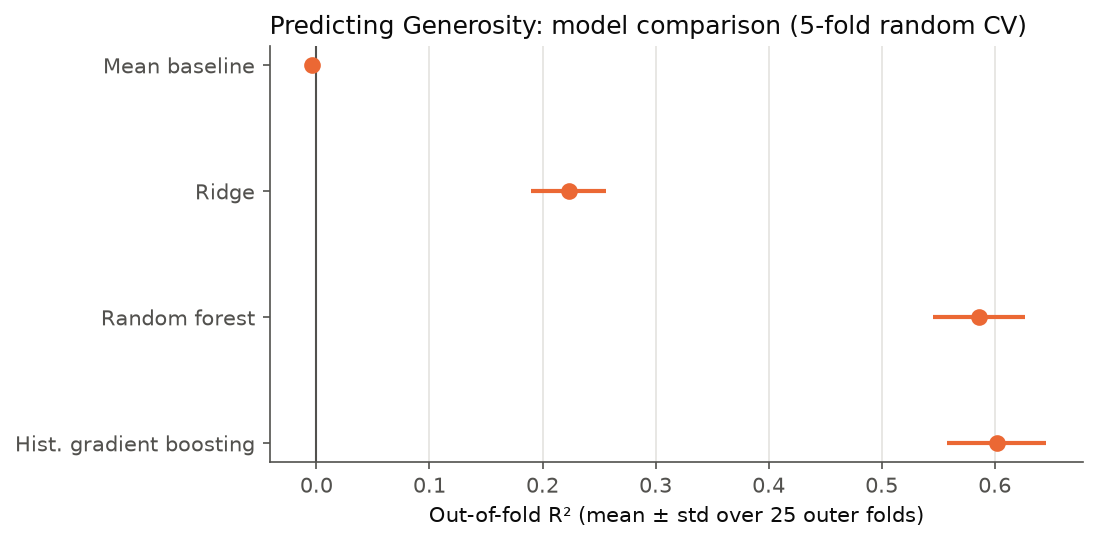

In [3]:
display(Markdown(cv_table(metrics, "random")))
display(Image(filename=str(REPO / "figures" / "model_comparison.png")))

The tree ensembles reach R² of about 0.6 under cross-validation, consistent with the
original split, and well above Ridge regression and the mean baseline.

## 3. What the model relies on

Permutation importance computed on the held-out folds of each outer split, and partial
dependence of the best model for its top three features:

| Feature | Drop in R² when permuted (mean ± std over folds) |
|---|---|
| Log GDP per capita | 0.438 ± 0.056 |
| Positive affect | 0.229 ± 0.038 |
| Healthy life expectancy at birth | 0.225 ± 0.033 |
| Freedom to make life choices | 0.210 ± 0.042 |
| Perceptions of corruption | 0.164 ± 0.021 |
| Negative affect | 0.093 ± 0.019 |
| Social support | 0.062 ± 0.012 |

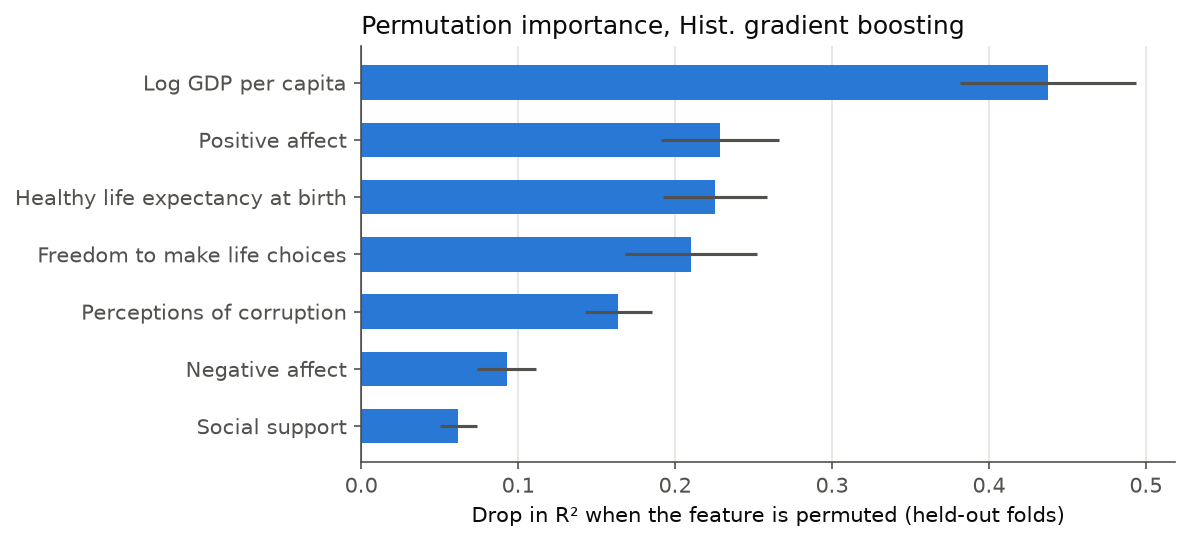

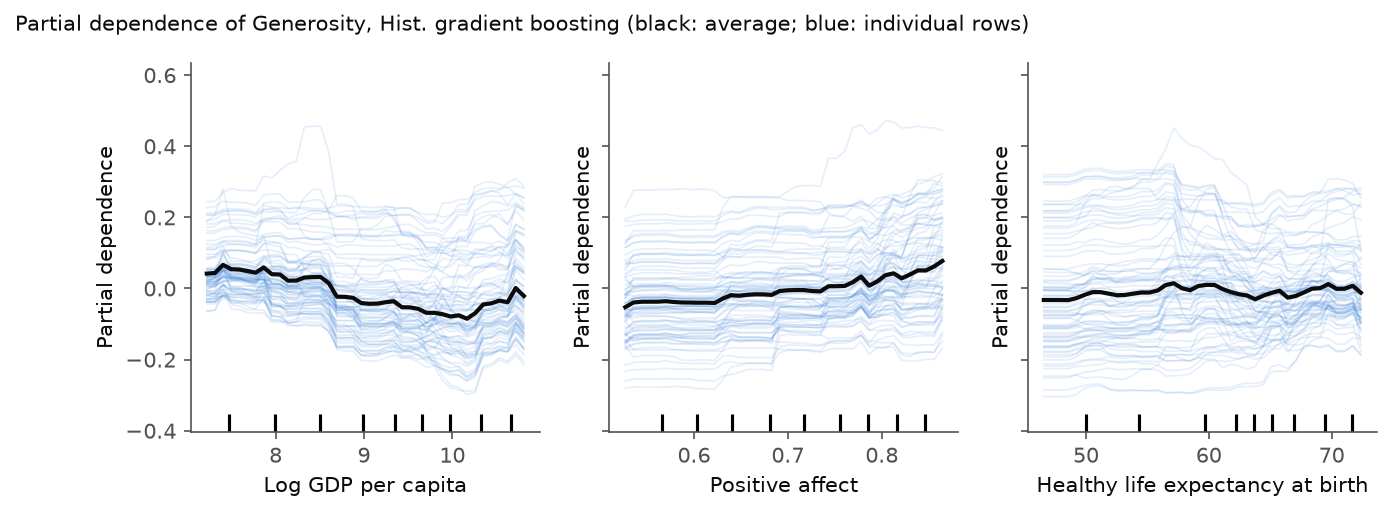

In [4]:
display(Markdown(importance_table(metrics)))
display(Image(filename=str(REPO / "figures" / "permutation_importance.png")))
display(Image(filename=str(REPO / "figures" / "partial_dependence.png")))

These are associations in a cross-country panel, not causal effects. See the README
for limitations.